# PS1 Part 1: Linear Models and Validation

### Preamble
We'll be loading some CO2 concentration data that is a commonly used dataset for model building of time series prediction. You will build a few baseline linear models and assess them using some of the tools we discussed in class. Which model is best? Let's find out.

First let's just load the data and take a look at it:

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml
from datetime import datetime, timedelta
import pandas as pd
from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()
sns.set_context('notebook')

# Fetch the data
mauna_lao = fetch_openml('mauna-loa-atmospheric-co2', as_frame = False)
print(mauna_lao.DESCR)
data = mauna_lao.data
# Assemble the day/time from the data columns so we can plot it
d1958 = datetime(year=1958,month=1,day=1)
time = [datetime(int(d[0]),int(d[1]),int(d[2])) for d in data]
X = np.array([1958+(t-d1958)/timedelta(days=365.2425) for t in time]).T
X = X.reshape(-1,1)  # Make it a column to make scikit happy
y = np.array(mauna_lao.target)

**Weekly carbon-dioxide concentration averages derived from continuous air samples for the Mauna Loa Observatory, Hawaii, U.S.A.**<br><br>
These weekly averages are ultimately based on measurements of 4 air samples per hour taken atop intake lines on several towers during steady periods of CO2 concentration of not less than 6 hours per day; if no such periods are available on a given day, then no data are used for that day. The _Weight_ column gives the number of days used in each weekly average. _Flag_ codes are explained in the NDP writeup, available electronically from the [home page](http://cdiac.ess-dive.lbl.gov/ftp/trends/co2/sio-keel-flask/maunaloa_c.dat) of this data set. CO2 concentrations are in terms of the 1999 calibration scale (Keeling et al., 2002) available electronically from the references in the NDP writeup which can be accessed from the home page of this data set.
<br><br>
### Feature Descriptions
_co2_: average co2 concentration in ppvm <br>
_year_: year of concent

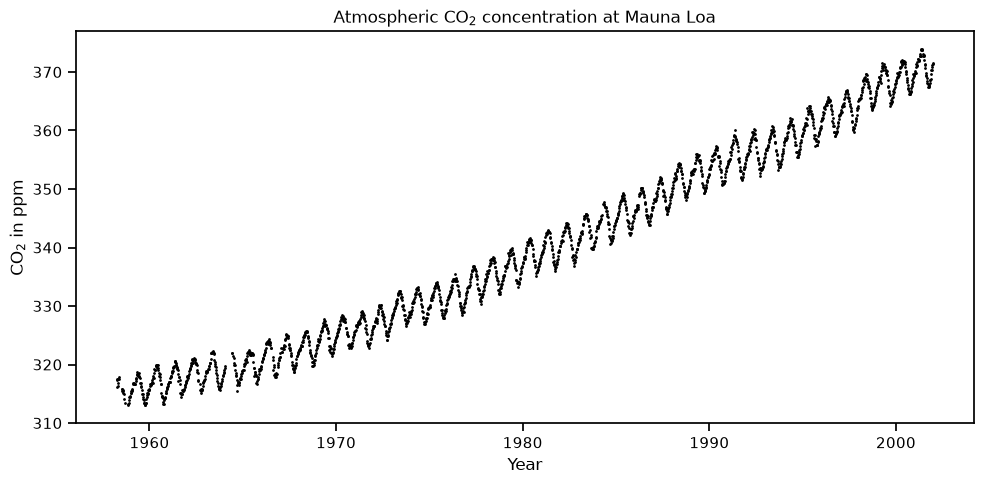

In [2]:
# Plot the data
plt.figure(figsize=(10,5))    # Initialize empty figure
plt.scatter(X, y, c='k',s=1) # Scatterplot of data
plt.xlabel("Year")
plt.ylabel(r"CO$_2$ in ppm")
plt.title(r"Atmospheric CO$_2$ concentration at Mauna Loa")
plt.tight_layout()
plt.show()

In [3]:
y[:100]

array([316.1, 317.3, 317.6, 317.5, 316.4, 316.9, 317.5, 317.9, 315.8,
       315.8, 315.4, 315.5, 315.6, 315.1, 315. , 314.1, 313.5, 313. ,
       313.2, 313.5, 314. , 314.5, 314.4, 314.7, 315.2, 315.2, 315.5,
       315.6, 315.8, 315.4, 316.9, 316.6, 316.6, 316.8, 316.7, 316.7,
       317.7, 317.1, 317.6, 318.3, 318.2, 318.7, 318. , 318.4, 318.5,
       318.1, 317.8, 317.7, 316.8, 316.8, 316.4, 316.1, 315.6, 314.9,
       315. , 314.1, 314.4, 313.9, 313.5, 313.5, 313. , 313.1, 313.4,
       313.4, 314.1, 314.4, 314.8, 315.2, 315.1, 315. , 315.6, 315.8,
       315.7, 315.7, 316.4, 316.7, 316.5, 316.6, 316.6, 316.9, 317.4,
       317. , 316.9, 317.7, 318. , 317.7, 318.6, 319.3, 319. , 319. ,
       319.7, 319.9, 319.8, 320. , 320. , 319.4, 320. , 319.4, 319. ,
       318.1])

### Linear Models

Construct the following linear models:
1. Model 1: "Vanilla" Linear Regression, that is, where $CO_2 = a+b \cdot time$
2. Model 2: Quadratic Regression, where $CO_2 = a+b \cdot t + c\cdot t^2$
3. Model 3: A more complex "linear" model with the following additive terms $CO_2=a+b\cdot t+c\cdot sin(\omega\cdot t)$:
  * a linear (in time) term
  * a sinusoidal additive term with period such that the peak-to-peak of the sinsusoid is roughly ~1 year and phase shift of zero (set $\omega$ as appropriate to match the peaks)
4. Model 4: A "linear" model with the following additive terms ($CO_2=a+b\cdot t+c\cdot t^2+d\cdot sin(\omega\cdot t)$:
  * a quadratic (in time) polynomial
  * a sinusoidal additive term with period such that the peak-to-peak of the sinsusoid is roughly ~1 year and phase shift of zero (set $\omega$ as appropriate to match the peaks)
  
Evauate these models using **the appropriate kind of Cross Validation** for each of the following amounts of Training data:
1. N=50 Training Data Points
2. N=100
3. N=200
4. N=500
5. N=1000
6. N=2000

**Question**: Before you even construct the models or do any coding below, what is your initial guess or intuition behind how each of those four models will perform? Note: there is no right or wrong answer to this part of the assignment and this question will only be graded on completeness, not accuracy. It's intent is to get you to think about and write down your preliminary intuition regarding what you think will happen before you actually implement anything, based on your approximate understanding of how functions of the above complexity *should* perform as N increases.

**Student Response:** From Plotting the data, one can tell that relation can apparently be approximated by an increasing oscillating function in time where the growth seems to be linear. Thus intuitively, model 3 seems to be a good choice for me.


**Question**: What is the appropriate kind of Cross Validation to perform in this case if we want a correct Out of Sample estimate of our Test MSE?

**Student Response:** Since we are dealing with tempora data, Time Series CV seems to be the appropriate kind of cross validation for this problem.

Now, for each of the above models and training data sizes:
* Plot the predicted CO2 as a function of time, including the actual data, for each of the N=X training data examples. This should correspond to six plots (one for each amount of training data) if you plot all models on the same plot, or 6x4 = 24 plots if you plot each model and training data plot separately.
* Create a [Learning Curve](https://scikit-learn.org/stable/auto_examples/model_selection/plot_learning_curve.html) plot for the model which plots its Training and Test MSE as a function of training data. That is, plot how Training and Testing MSE change as you increase the training data for each model. This could be a single plot for all four models (8 lines on the plot) or four different plots corresponding to the learning curve of each model separately.

In [4]:
import numpy as np

X_train_100 = X[:100]
y_train_100 = y[:100]
X_test = X[100:200]
print("Shape of X_train_100: %s" % str(X_train_100.shape))
print("Beginning of X_train_100: %s" % str(X_train_100[0:5]))
print("Shape of y_train_100: %s" % str(y_train_100.shape))
print("Beginning of y_train_100: %s" % str(y_train_100[0:5]))

print('Shape of X_test: %s' % str(X_test.shape))
print("Beginning of X_test: %s" % str(X_test[0:5]))

### Modify the below code. You can leave the code above as is. ###



Shape of X_train_100: (100, 1)
Beginning of X_train_100: [[1958.23819791]
 [1958.25736326]
 [1958.27652861]
 [1958.29569396]
 [1958.31485931]]
Shape of y_train_100: (100,)
Beginning of y_train_100: [316.1 317.3 317.6 317.5 316.4]
Shape of X_test: (100, 1)
Beginning of X_test: [[1960.51887445]
 [1960.5380398 ]
 [1960.55720514]
 [1960.57637049]
 [1960.59553584]]


In [11]:
# Insert Modeling Building or Plotting code here
# Note, you may implement these however you see fit
# Ex: using an existing library, solving the Normal Eqns
#     implementing your own SGD solver for them. Your Choice.
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.metrics import mean_squared_error
sgd = SGDRegressor()
lr = LinearRegression()



In [24]:
## Feature definition for every model

omega = 2 * np.pi
T0 = 1958.0


def features(X, model):
    t = X[:, 0] - T0
    if model == 1:
        cols = [t]
    elif model == 2:
        cols = [t, t**2]
    elif model == 3:
        cols = [t, np.sin(omega * t)]
    elif model == 4:
        cols = [t, t**2, np.sin(omega * t)]
    return np.column_stack(cols)

model_names = {
    1: "linear",
    2: "quadratic",
    3: "linear + sinusoidal",
    4: "quadratic + sinusoidal"
}

In [18]:
## Fit and score models
def fit_and_score(model, train_idx, test_idx):
    feature_train = features(X[train_idx], model)
    feature_test = features(X[test_idx], model)
    model = lr.fit(feature_train, y[train_idx])

    train_mse = mean_squared_error(y[train_idx], model.predict(feature_train))
    test_mse = mean_squared_error(y[test_idx], model.predict(feature_test))
    return model, train_mse, test_mse

In [ ]:
## Time Series Cross Validation
def rolling_forward_cv(model, N, test_size=100, n_folds=5):
    n = len(X)
    last_start = n - N- test_size
    if last_start < 0:
        raise ValueError(f"N={N} too large for test_size={test_size}")
    
    starts = np.unique(np.linspace(0, last_start, n_folds).astype(int))

    train_mses, test_mses = [], []

    for s in starts:
        train_idx = np.arange(s, s+N)
        test_idx = np.arange(s +N, s+N+test_size)
        _, tr, te = fit_and_score(model, train_idx, test_idx)
        train_mses.append(tr)
        test_mses.append(te)
    return np.mean(train_mses), np.mean(test_mses)


In [25]:
Ns = [50, 100, 200, 500, 1000, 2000]
rows = []
for model in [1, 2, 3, 4]:
    for N in Ns:
        tr, te = rolling_forward_cv(model, N)
        rows.append({"model": model_names[model], "N": N, "train_mse": tr, "test_mse": te})

results = pd.DataFrame(rows)
print(results.pivot(index="N", columns="model", values="test_mse").round(2))

model  linear  linear + sinusoidal  quadratic  quadratic + sinusoidal
N                                                                    
50      44.88                 3.43     850.41                 2894.31
100      8.25                 1.63      40.29                   12.27
200      5.42                 1.87      11.29                    4.28
500      6.04                 1.95       5.51                    2.21
1000     6.17                 2.46       4.93                    1.03
2000    13.70                 9.97       5.16                    1.41


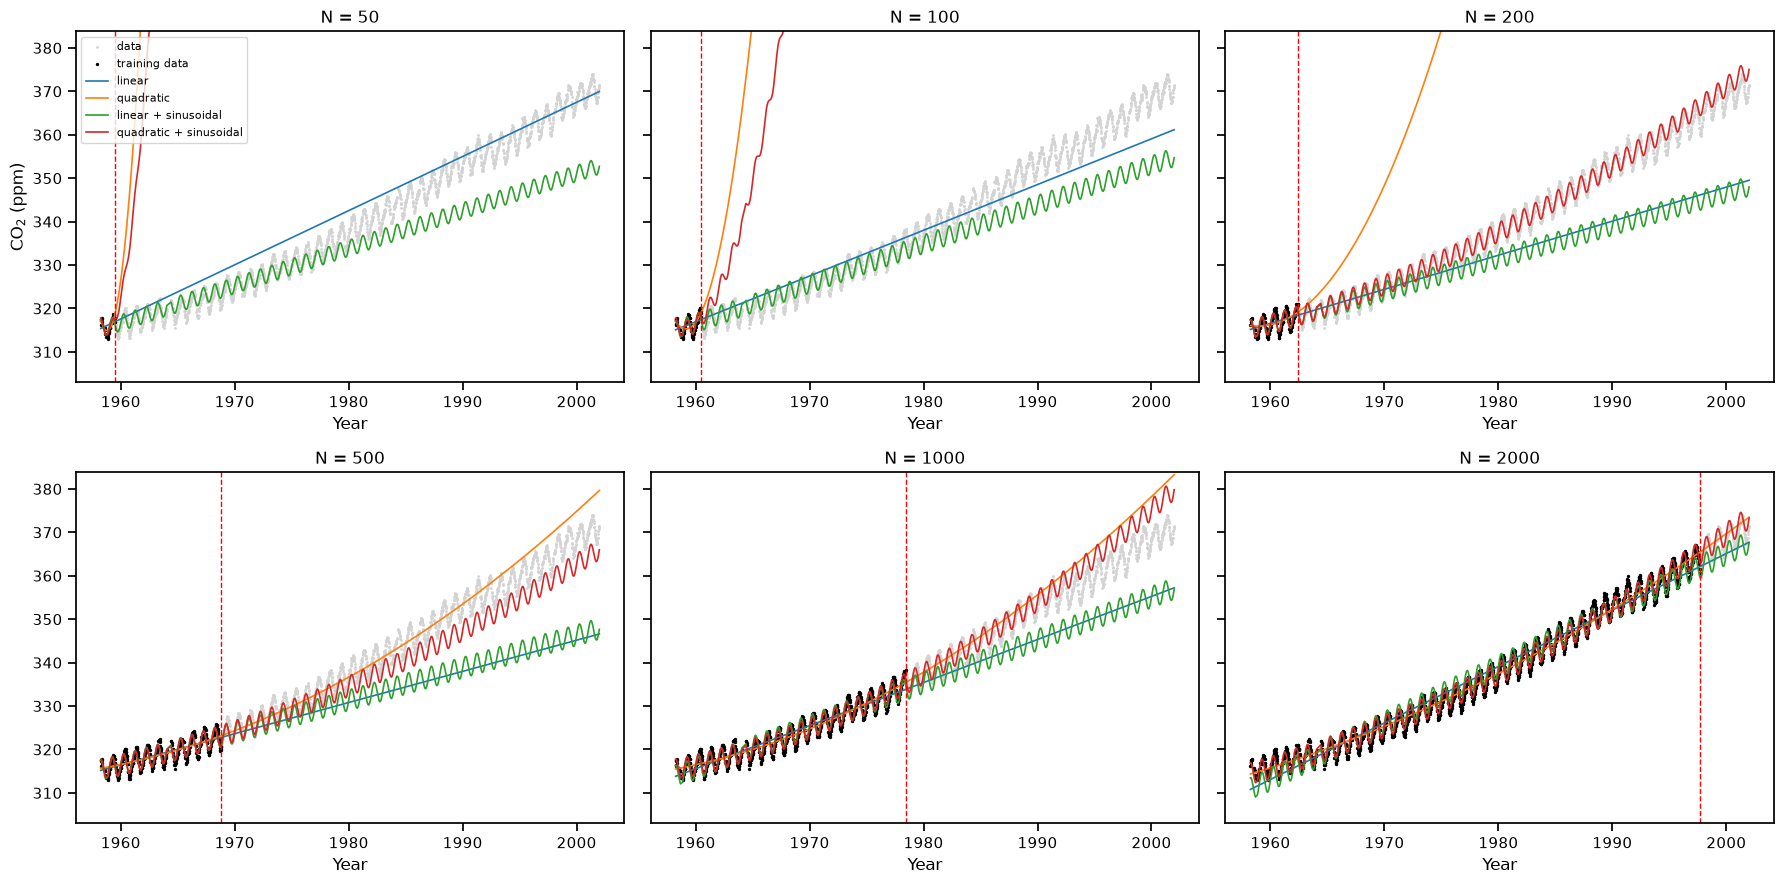

In [26]:
from matplotlib import pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharey=True)
for ax, N in zip(axes.ravel(), Ns):
    train_idx = np.arange(N)
    ax.scatter(X, y, c="lightgray", s=1, label="data")
    ax.scatter(X[train_idx], y[train_idx], c="k", s=2, label="training data")

    for model_id in [1, 2, 3, 4]:
        model = LinearRegression().fit(features(X[train_idx], model_id), y[train_idx])
        ax.plot(X[:, 0], model.predict(features(X, model_id)), lw=1.2, label=model_names[model_id])

    ax.axvline(X[N - 1, 0], color="r", ls="--", lw=1)   # end of training data
    ax.set_title(f"N = {N}")
    ax.set_xlabel("Year")

axes[0, 0].set_ylabel("CO$_2$ (ppm)")
axes[0, 0].set_ylim(y.min() - 10, y.max() + 10)   # keep runaway extrapolations from wrecking the axis
axes[0, 0].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()


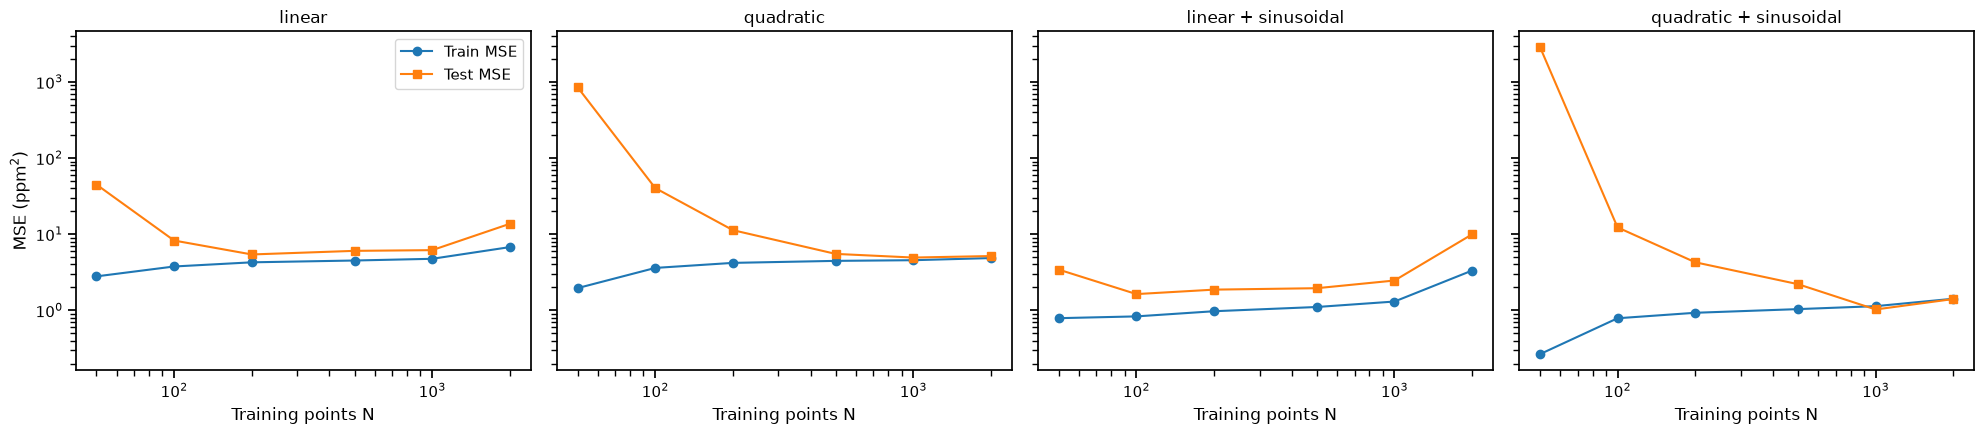

In [28]:
## Learning Curve
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
for ax, model_id in zip(axes, [1, 2, 3, 4]):
    r = results[results.model == model_names[model_id]]
    ax.plot(r.N, r.train_mse, "o-", label="Train MSE")
    ax.plot(r.N, r.test_mse,  "s-", label="Test MSE")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(model_names[model_id])
    ax.set_xlabel("Training points N")
axes[0].set_ylabel("MSE (ppm$^2$)")
axes[0].legend()
plt.tight_layout()
plt.show()


**Question**: Which Model appears to perform best in the N=50 or N=100 Condition? Why is this?

**Student Response:**  Model 3 (linear + sinusoid) performs best, with a test MSE of about 3.4 at N=50 and 1.6 at N=100. With only one or two years of weekly data, the biggest pattern in the data is the seasonal cycle, and over such a short window the long-term trend looks like a straight line. Model 3 captures both with only three parameters, so its estimates are stable. The quadratic models do much worse even though Model 4 has the lowest training error (about 0.27 at N=50). Over a one-year window, the t² coefficient is barely determined by the data, so it ends up fitting noise. When you extrapolate to the test period, that curvature blows up, which explains test MSEs of 850 and 2894. This is high variance and overfitting: the more flexible model fits the training data better but generalizes much worse. The plain linear model can't represent the seasonal cycle, which costs it, but it doesn't extrapolate wildly.

**Question**: Which Model appears to perform best as the N=200 to 500? Why is this?

**Student Response:** Model 3 is still the best (test MSE about 1.9 at both N=200 and N=500), but Model 4 is catching up quickly (4.3 → 2.2). Over 4 to 10 years, the curvature of the CO₂ trend is still small, so a linear trend plus the seasonal term is a good local approximation. With more data, the t² coefficient gets estimated more reliably, so the quadratic models stop extrapolating wildly. At N=500, Quadratic even does slightly better than Linear (5.5 vs. 6.0). Both models without the sine term stay around 5–6 MSE, because they can't model the yearly oscillation. That leftover error is bias.

**Question**: Which Model appears to perform best as N = 2000? Why is this?

**Student Response:** Model 4 (quadratic + sinusoid) is clearly the best, with a test MSE of about 1.4, compared with 5.2 for Quadratic, 10.0 for Linear + sin and 13.7 for Linear. Over about 40 years, CO₂ growth visibly speeds up, so a straight-line trend underfits. You can see this because Model 3's training MSE also rises, to about 3.3, which means the bias is coming from the model's form, not from too little data. With 2000 points, there's enough data to pin down the quadratic coefficient, so the extra flexibility no longer adds much variance. Model 4 is the only model with both the curvature and the seasonal cycle, so it has low bias and low variance. Its train and test MSE are almost equal (1.42 vs. 1.41), which suggests it isn't overfitting. The remaining error of about 1 ppm² comes mostly from the zero-phase sinusoid, which doesn't line up exactly with the real seasonal peak in May, and from year-to-year variation that none of the models capture.